# Redes Neuronales III — Evaluación multiclase

**Estudiante:** Ruby Dayana Cárdenas Gómez  
**Universidad:** Universidad de Cundinamarca  
**CADI:** Deep Learning — Conceptos  
**Docente:** Nidia Stella García Roa

Esta práctica construye una red neuronal multiclase con TensorFlow y Keras para reconocer dígitos manuscritos. Se documentan la distribución y el preprocesamiento de los datos, la división **train/dev/test**, la regularización y las métricas por clase.


## 1 Objetivos

- Preparar datos de imágenes sin introducir fuga de información.
- Entrenar una red densa regularizada para diez clases.
- Calcular Accuracy, Precision, Recall y F1 macro.
- Interpretar la matriz de confusión y los errores más frecuentes.


In [1]:
import json
import os
import random
import warnings

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from sklearn.datasets import load_digits
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             precision_recall_fscore_support)
from sklearn.model_selection import train_test_split
from tensorflow.keras import Sequential, regularizers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.utils import to_categorical

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
sns.set_theme(style="whitegrid", palette="deep")

print("TensorFlow:", tf.__version__)
print("Semilla:", SEED)


TensorFlow: 2.20.0
Semilla: 42


## 2 Datos y exploración

`load_digits` contiene 1 797 imágenes de 8 por 8 píxeles. Cada píxel tiene una intensidad entre 0 y 16 y cada ejemplo pertenece a una de diez clases, de 0 a 9.


In [2]:
digits = load_digits()
X_images = digits.images
X = digits.data.astype("float32")
y = digits.target.astype("int64")

distribucion = pd.Series(y).value_counts().sort_index()
display(pd.DataFrame({
    "Dígito": distribucion.index,
    "Cantidad": distribucion.values,
    "Porcentaje": (distribucion.values / len(y) * 100).round(2),
}))
print("Imágenes:", X_images.shape, "Matriz aplanada:", X.shape)


,Dígito,Cantidad,Porcentaje
0,0,178,9.91
1,1,182,10.13
2,2,177,9.85
3,3,183,10.18
4,4,181,10.07
5,5,182,10.13
6,6,181,10.07
7,7,179,9.96
8,8,174,9.68
9,9,180,10.02


Imágenes: (1797, 8, 8) Matriz aplanada: (1797, 64)


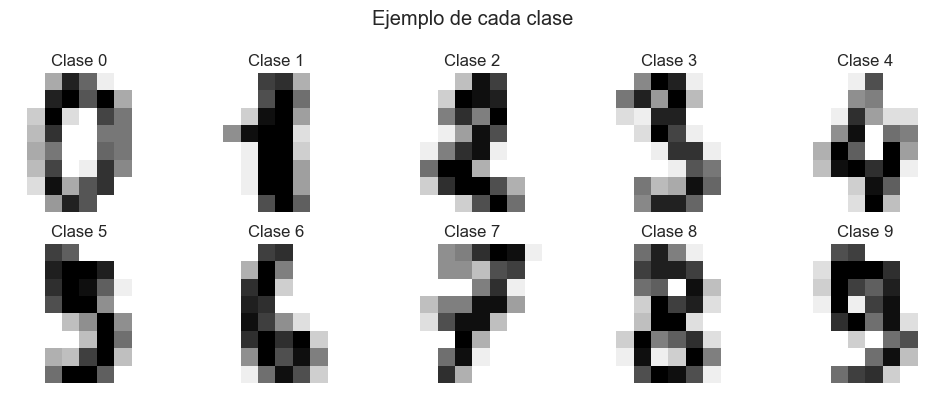

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for digito, ax in enumerate(axes.ravel()):
    indice = np.where(y == digito)[0][0]
    ax.imshow(X_images[indice], cmap="gray_r")
    ax.set_title(f"Clase {digito}")
    ax.axis("off")
plt.suptitle("Ejemplo de cada clase")
plt.tight_layout()
plt.show()


## 3 Separación train dev test

La división es estratificada para mantener la distribución de los diez dígitos. Train representa 70 %, dev 15 % y test 15 %. Dev orienta el entrenamiento y test se reserva para la medición final.


In [4]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SEED, stratify=y
)
X_dev, X_test, y_dev, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp
)

particiones = pd.DataFrame({
    "Partición": ["Train", "Dev", "Test"],
    "Registros": [len(X_train), len(X_dev), len(X_test)],
})
particiones["Porcentaje"] = (particiones["Registros"] / len(X) * 100).round(2)
display(particiones)


,Partición,Registros,Porcentaje
0,Train,1257,69.95
1,Dev,270,15.03
2,Test,270,15.03


## 4 Preprocesamiento

Las intensidades se dividen por 16 para llevarlas al intervalo de 0 a 1. Las etiquetas se transforman a one hot encoding con `to_categorical`, formato compatible con softmax y entropía cruzada categórica.


In [5]:
X_train_n = X_train / 16.0
X_dev_n = X_dev / 16.0
X_test_n = X_test / 16.0

y_train_oh = to_categorical(y_train, num_classes=10)
y_dev_oh = to_categorical(y_dev, num_classes=10)
y_test_oh = to_categorical(y_test, num_classes=10)

print("Rango train:", float(X_train_n.min()), "a", float(X_train_n.max()))
print("Forma de etiquetas one hot:", y_train_oh.shape)


Rango train: 0.0 a 1.0
Forma de etiquetas one hot: (1257, 10)


## 5 Modelo regularizado

La red contiene dos capas ocultas. La regularización L2 penaliza pesos grandes y Dropout desactiva neuronas aleatoriamente durante el entrenamiento. Adam adapta el paso de actualización de cada parámetro.


In [6]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)

modelo = Sequential([
    Input(shape=(64,)),
    Dense(128, activation="relu", kernel_initializer="he_normal",
          kernel_regularizer=regularizers.l2(1e-4)),
    Dropout(0.25),
    Dense(64, activation="relu", kernel_initializer="he_normal",
          kernel_regularizer=regularizers.l2(1e-4)),
    Dropout(0.20),
    Dense(10, activation="softmax"),
])

modelo.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)
modelo.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,226 (67.29 KB)

 Trainable params: 17,226 (67.29 KB)

 Non-trainable params: 0 (0.00 B)

## 6 Entrenamiento y control del sobreajuste

Early Stopping detiene el proceso cuando la pérdida de dev deja de mejorar y restaura los mejores pesos. ReduceLROnPlateau disminuye el learning rate cuando la optimización se estanca.


In [7]:
callbacks = [
    EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-5),
]

historia = modelo.fit(
    X_train_n, y_train_oh,
    validation_data=(X_dev_n, y_dev_oh),
    epochs=100,
    batch_size=32,
    callbacks=callbacks,
    verbose=0,
)

print("Épocas ejecutadas:", len(historia.history["loss"]))
print("Mejor val_accuracy:", round(max(historia.history["val_accuracy"]), 4))


W0000 00:00:1791684590.529316 62138895 op_level_cost_estimator.cc:743] Invalid device specifications for CPU: type: "CPU" model: "0" num_cores: 10 environment { key: "cpu_instruction_set" value: "ARM NEON" } environment { key: "eigen" value: "3.4.90" } l1_cache_size: 16384 l2_cache_size: 524288 l3_cache_size: 524288 memory_size: 268435456


W0000 00:00:1791684592.317890 62138895 op_level_cost_estimator.cc:743] Invalid device specifications for CPU: type: "CPU" model: "0" num_cores: 10 environment { key: "cpu_instruction_set" value: "ARM NEON" } environment { key: "eigen" value: "3.4.90" } l1_cache_size: 16384 l2_cache_size: 524288 l3_cache_size: 524288 memory_size: 268435456


W0000 00:00:1791684593.506231 62138895 op_level_cost_estimator.cc:743] Invalid device specifications for CPU: type: "CPU" model: "0" num_cores: 10 environment { key: "cpu_instruction_set" value: "ARM NEON" } environment { key: "eigen" value: "3.4.90" } l1_cache_size: 16384 l2_cache_size: 524288 l3_cache_size: 524288 memory_size: 268435456


Épocas ejecutadas: 35
Mejor val_accuracy: 0.9778


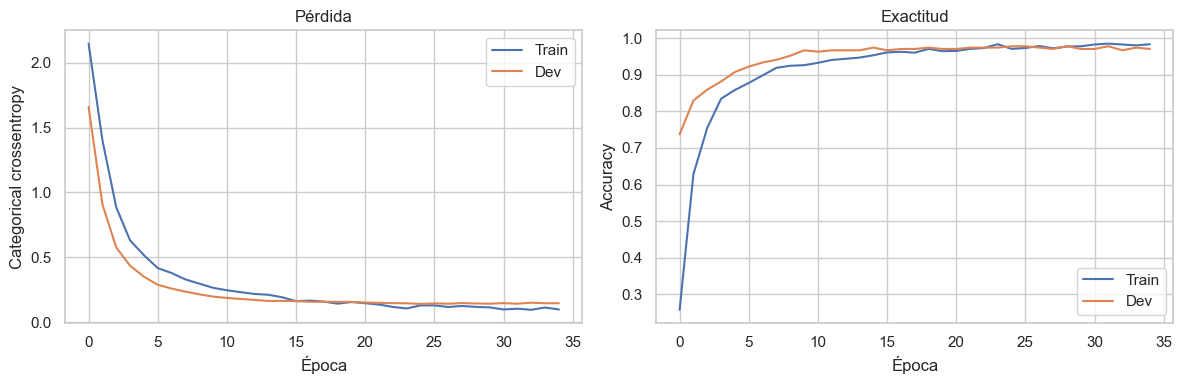

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(historia.history["loss"], label="Train")
axes[0].plot(historia.history["val_loss"], label="Dev")
axes[0].set(title="Pérdida", xlabel="Época", ylabel="Categorical crossentropy")
axes[1].plot(historia.history["accuracy"], label="Train")
axes[1].plot(historia.history["val_accuracy"], label="Dev")
axes[1].set(title="Exactitud", xlabel="Época", ylabel="Accuracy")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()


## 7 Métricas de evaluación

Accuracy mide el porcentaje total de aciertos. Precision macro promedia cuántas predicciones de cada clase fueron correctas. Recall macro promedia la proporción recuperada de cada clase. F1 macro combina Precision y Recall y da el mismo peso a los diez dígitos.


In [9]:
probabilidades = modelo.predict(X_test_n, verbose=0)
y_pred = probabilidades.argmax(axis=1)

precision_macro, recall_macro, f1_macro, _ = precision_recall_fscore_support(
    y_test, y_pred, average="macro", zero_division=0
)
metricas = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision macro": precision_macro,
    "Recall macro": recall_macro,
    "F1 macro": f1_macro,
}
display(pd.DataFrame([metricas]).style.format("{:.4f}"))


,Accuracy,Precision macro,Recall macro,F1 macro
0,0.9852,0.9854,0.9850,0.9852


In [10]:
reporte = classification_report(y_test, y_pred, output_dict=True, zero_division=0)
reporte_clases = pd.DataFrame(reporte).T.iloc[:10][["precision", "recall", "f1-score", "support"]]
display(reporte_clases.style.format({
    "precision": "{:.4f}", "recall": "{:.4f}",
    "f1-score": "{:.4f}", "support": "{:.0f}",
}))


,precision,recall,f1-score,support
0,1.0000,1.0000,1.0000,27
1,0.9310,0.9643,0.9474,28
2,1.0000,1.0000,1.0000,26
3,1.0000,1.0000,1.0000,28
4,1.0000,1.0000,1.0000,27
5,1.0000,1.0000,1.0000,27
6,1.0000,0.9630,0.9811,27
7,1.0000,1.0000,1.0000,27
8,0.9231,0.9231,0.9231,26
9,1.0000,1.0000,1.0000,27


## 8 Matriz de confusión

La diagonal contiene los aciertos. Los valores fuera de ella muestran qué dígitos se confunden y permiten identificar errores que Accuracy no explica.


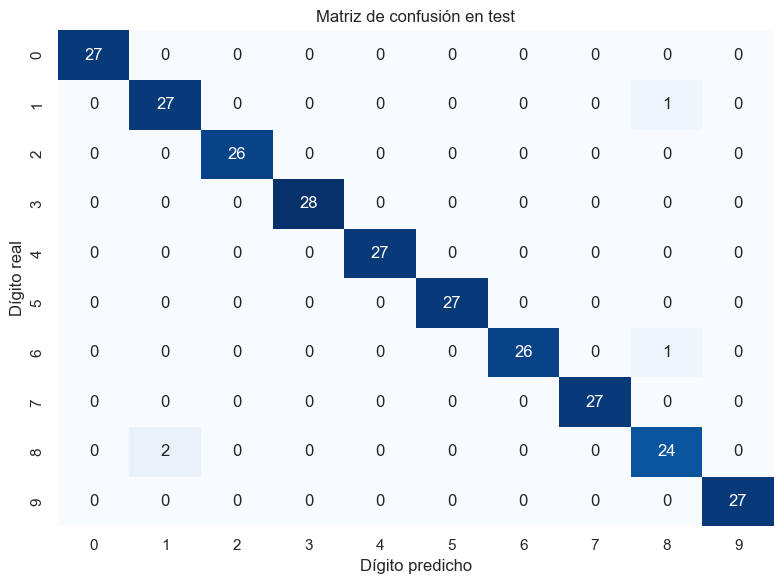

In [11]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title("Matriz de confusión en test")
plt.xlabel("Dígito predicho")
plt.ylabel("Dígito real")
plt.tight_layout()
plt.show()


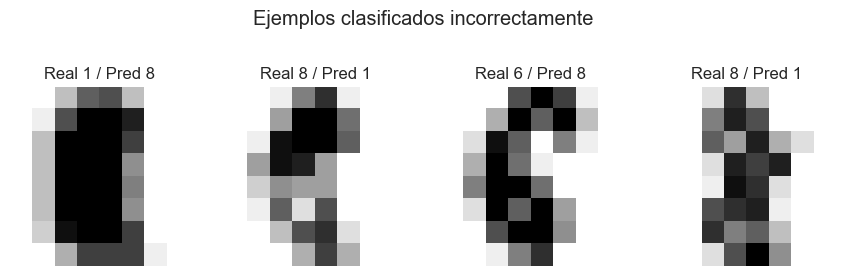

In [12]:
errores = np.where(y_test != y_pred)[0]
cantidad = min(8, len(errores))
fig, axes = plt.subplots(1, max(cantidad, 1), figsize=(2.2 * max(cantidad, 1), 2.8))
axes = np.atleast_1d(axes)
for ax, indice_local in zip(axes, errores[:cantidad]):
    ax.imshow(X_test[indice_local].reshape(8, 8), cmap="gray_r")
    ax.set_title(f"Real {y_test[indice_local]} / Pred {y_pred[indice_local]}")
    ax.axis("off")
plt.suptitle("Ejemplos clasificados incorrectamente")
plt.tight_layout(rect=[0, 0, 1, 0.90])
plt.show()


## 9 Distribución de errores

Se cuentan las confusiones fuera de la diagonal. Esta tabla ayuda a priorizar las parejas de dígitos que requieren más datos o una arquitectura con mejor capacidad espacial.


In [13]:
confusiones = []
for real in range(10):
    for predicho in range(10):
        if real != predicho and cm[real, predicho] > 0:
            confusiones.append({"Real": real, "Predicho": predicho, "Casos": int(cm[real, predicho])})
confusiones_df = pd.DataFrame(confusiones).sort_values("Casos", ascending=False).reset_index(drop=True)
display(confusiones_df.head(10))


,Real,Predicho,Casos
0,8,1,2
1,1,8,1
2,6,8,1


## 10 Interpretación técnica

El conjunto presenta una distribución cercana al equilibrio, por lo que Accuracy y las métricas macro deberían ser similares. Si una clase obtiene Recall bajo, el modelo omite varios ejemplos reales de ese dígito. Si obtiene Precision baja, recibe predicciones que pertenecen a otras clases. Las imágenes de error permiten relacionar esas cifras con trazos visualmente ambiguos.


In [14]:
resultado_exportable = {
    "epochs": len(historia.history["loss"]),
    "metricas_test": {clave: round(float(valor), 6) for clave, valor in metricas.items()},
    "matriz_confusion": cm.tolist(),
    "errores_test": int((y_test != y_pred).sum()),
    "confusiones_principales": confusiones_df.head(5).to_dict(orient="records"),
}
print("RESULTADOS_JSON:" + json.dumps(resultado_exportable, ensure_ascii=False))


RESULTADOS_JSON:{"epochs": 35, "metricas_test": {"Accuracy": 0.985185, "Precision macro": 0.985411, "Recall macro": 0.985033, "F1 macro": 0.985158}, "matriz_confusion": [[27, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 27, 0, 0, 0, 0, 0, 0, 1, 0], [0, 0, 26, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 28, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 27, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 27, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 26, 0, 1, 0], [0, 0, 0, 0, 0, 0, 0, 27, 0, 0], [0, 2, 0, 0, 0, 0, 0, 0, 24, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 27]], "errores_test": 4, "confusiones_principales": [{"Real": 8, "Predicho": 1, "Casos": 2}, {"Real": 1, "Predicho": 8, "Casos": 1}, {"Real": 6, "Predicho": 8, "Casos": 1}]}


## 11 Conclusiones

La división estratificada y la normalización separada preservan la validez de la evaluación. La red combina Adam, L2, Dropout, reducción del learning rate y Early Stopping para mejorar la estabilidad. El reporte por clase, la matriz de confusión y las imágenes mal clasificadas ofrecen una lectura más completa que Accuracy por sí sola.
